<a href="https://www.selmilab.eu/"><img src="images/selmilab_logo_with_name_small.png" alt='Logo Selmilab' align='right'  width="144" height="33" /></a>

**Author:** Luigi Selmi <br>
**Version** 1.0.0 <br>
**Copyright:** 2026 Luigi Selmi <br>
**License:** MIT

<div class="alert alert-block alert-success">
<h3>Two days 2m temperature forecast using ECMWF Open Data</h3></div>

The ECMWF provides a subset of its forecasts as open data. The data can be downloaded anonimously without setting up an account. The [ecmwf.opendata](https://github.com/ecmwf/ecmwf-opendata) Python package provides the methods to access and download the data. The forecast are available for only one step, e.g. today at 12:00 and then adding 12 hours or a multiple of 12 hours for the nexts day. For example, a step of 36 hours for the forecast tomorrow at 12:00, or a step of 60 hours for the forecast two days from now at 12:00 . The data format is GRIB. Xarray can read the data if the [cgrib engine](https://github.com/ecmwf/cfgrib) is installed. Links to more info are in the references. The ECMWF makes [plots and charts](https://charts.ecmwf.int/) from weather data using [Metview](https://metview.readthedocs.io/en/latest/), a software platform for the analysis of weather data. In this notebook we use Xarray and Matplotlib. In the next sections of this notebook we will download the forecast of the 2m temperature for today, tomorrow at 12:00 (36 hours lead time) and in the next two days, (60 hours lead time).

### Google Colab
In order to run the notebook on Google Colab you have to install the following Python packages since they are not available by default. Unfortunately until July 2026 a notebook saved on Github from Google Colab is not visible from its GitHub repository for some unresolved Google Colab technical problem. So it is better to not save directly a notebook on GitHub from Google Colab.

In [1]:
#!pip -q install cartopy

In [2]:
#!pip -q install cfgrib

In [3]:
#!pip -q install ecmwf-opendata

In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy
from ecmwf.opendata import Client

We create an instance of the ECMWF client

In [2]:
client = Client("ecmwf", beta=False)

To ensure the stability of our systems and to preserve resources for our operational activities (network, compute, etc.), access to the open-data portal is limited to 500 simultaneous connections. This limit helps us guarantee reliable service for our operational users, especially during periods of high demand. For added reliability, the open-data is replicated across AWS, Azure, and Google Cloud. If you experience difficulties accessing the portal directly, you can also retrieve the data from these cloud platforms.


From the variables available we select the 2m temperature and the mean sea level pressure.

In [3]:
parameters = ['2t', 'msl']

Since we are going to call the service several times we define a function with the lead time as the only argument

In [4]:
def call_ecmwf(lead_time):
    '''
    This function calls the ECMWF Open Data service,
    write the GRIB file locally and returns its file
    name.
    '''
    txt = str(lead_time)
    file_name = 'data/forecast-' + txt + '-t2m-msl.grib'
    client.retrieve(
        date=0,
        time=0,
        step=str(lead_time),
        stream="oper",
        type="fc",
        levtype="sfc",
        param=parameters,
        target=file_name
    )
    return file_name

We call the ECMWF service for a first forecast today at 12:00

In [5]:
forecast_12_data = call_ecmwf(12)

20260731000000-12h-oper-fc.grib2:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

By downloading data from the ECMWF open data dataset, you agree to the terms: Attribution 4.0 International (CC BY 4.0). Please attribute ECMWF when downloading this data.


We load the data into Xarray. We can see from the description that the forecast is for today (time field) with a lead time (step) of 12 hours, that is today at 12:00.

In [7]:
ds1 = xr.load_dataset(forecast_12_data.strip(), engine="cfgrib")

We call the ECMWF service a 2nd time for the t2m and msl forecast for tomorrow at the same time, 12:00.

In [15]:
forecast_36_data = call_ecmwf(36)

20260731000000-36h-oper-fc.grib2:   0%|          | 0.00/1.15M [00:00<?, ?B/s]

In [16]:
ds2 = xr.load_dataset(forecast_36_data, engine="cfgrib")

Finally, we call the ECMWF service a third time for a forecast two days ahead at the same time 12:00

In [17]:
forecast_60_data = call_ecmwf(60)

20260731000000-60h-oper-fc.grib2:   0%|          | 0.00/1.15M [00:00<?, ?B/s]

In [18]:
ds3 = xr.load_dataset(forecast_60_data, engine="cfgrib")

We will plot the 2m temperature datasets several times so better to define a function

In [19]:
def plot_t2m_forecast(xr_dataset, colorbar=True):
    plt.figure(figsize=(20,8))
    ax = plt.axes(projection=ccrs.PlateCarree())
    ax.gridlines(draw_labels=True, linestyle='--')
    ax.add_feature(cartopy.feature.OCEAN)
    ax.add_feature(cartopy.feature.LAND, edgecolor='black')
    ax.add_feature(cartopy.feature.LAKES, edgecolor='black')
    ax.add_feature(cartopy.feature.RIVERS)
    ax.add_feature(cfeature.BORDERS, linestyle=':')
    ax.coastlines()
    xr_dataset.plot(ax=ax, add_colorbar=colorbar, cmap='jet')

## 2m surface temperature forecasts
The 2m temperature forecast (t2m) dataset returned by the service covers the entire planet but we will focus over the european region.

In [20]:
bb_north = 60.0
bb_south = 35.0
bb_west = -10.0
bb_east = 40.0

We plot the 2m temperature forecast for today at 12:00

In [21]:
temperature2m_1 = ds1['t2m'].sel(latitude = slice(bb_north, bb_south),
                                 longitude = slice(bb_west, bb_east))

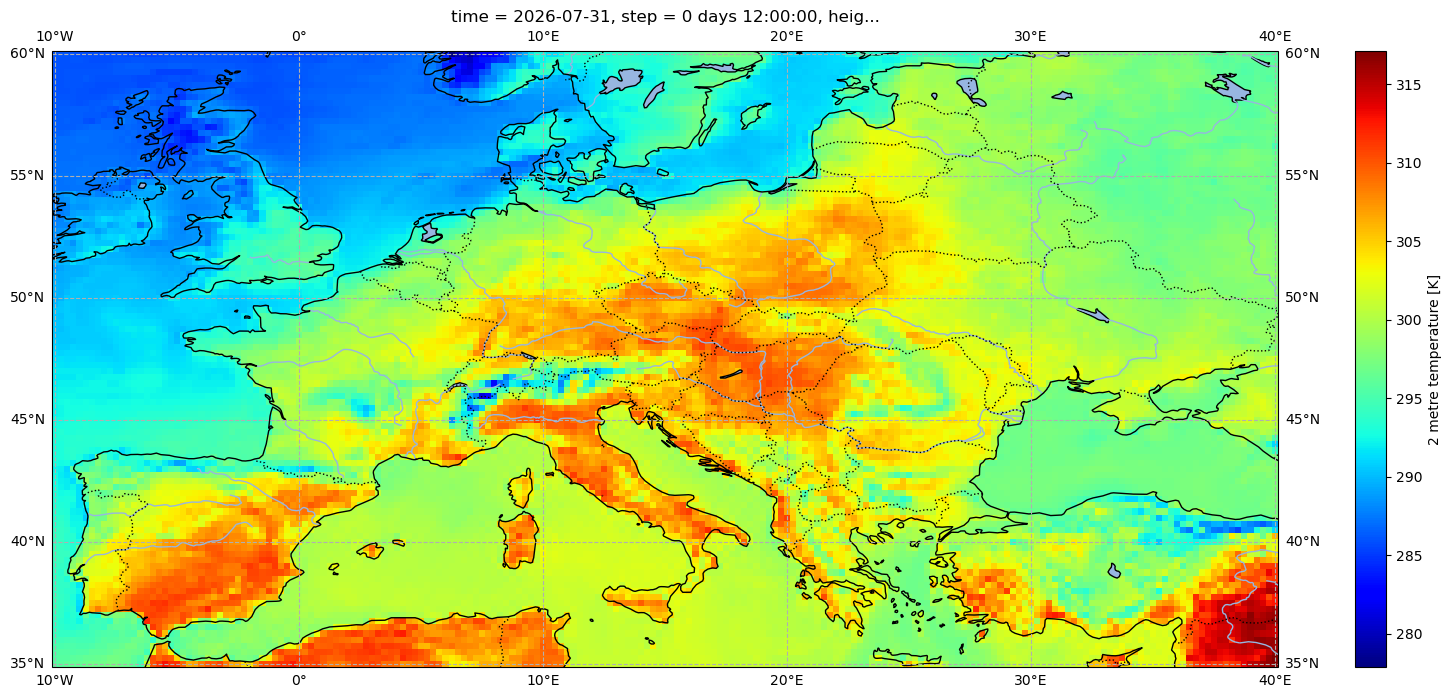

In [22]:
plot_t2m_forecast(temperature2m_1);

We plot the forecast for tomorrow at 12:00. We can read on the plot title the time of the request and the lead time: step one day at 12:00

In [23]:
temperature2m_2 = ds2['t2m'].sel(latitude = slice(bb_north, bb_south),
                                 longitude = slice(bb_west, bb_east))

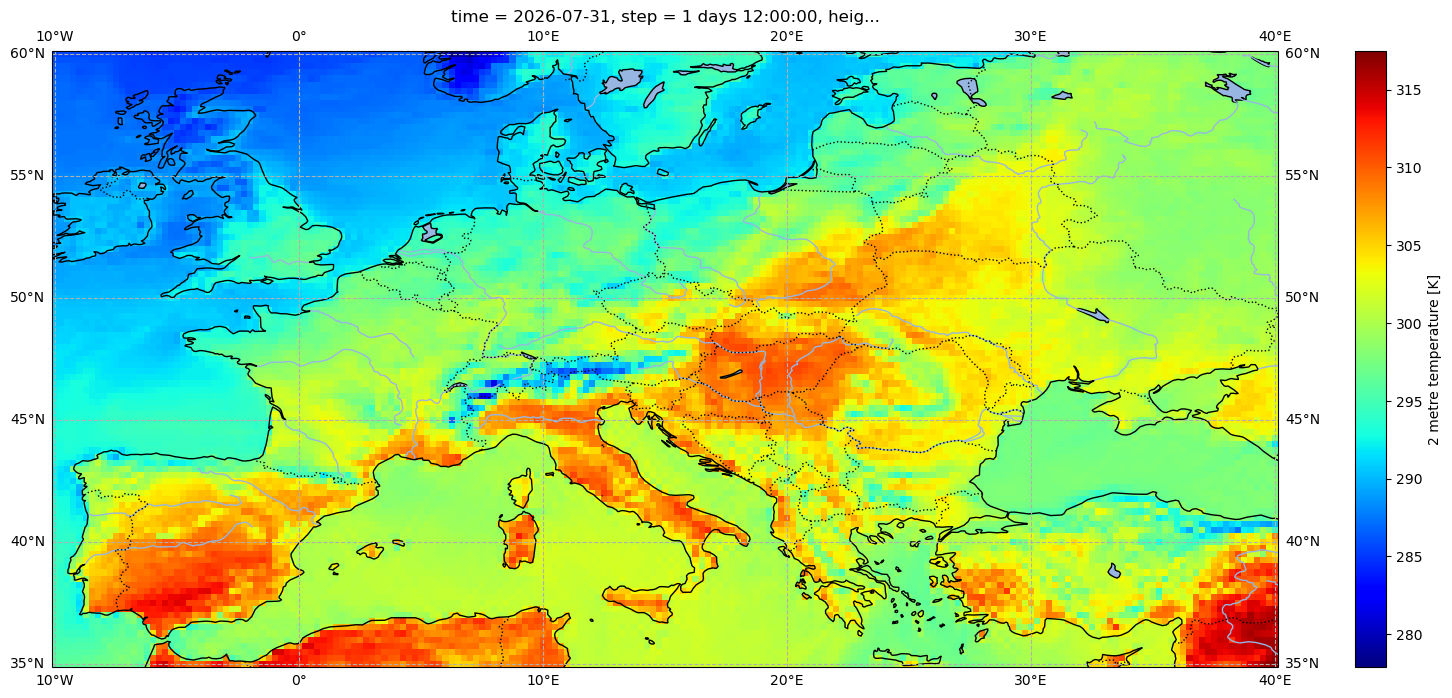

In [24]:
plot_t2m_forecast(temperature2m_2);

And finally the plot for the 2m temperature forecast two days (step=2) from now at 12:00

In [25]:
temperature2m_3 = ds3['t2m'].sel(latitude = slice(bb_north, bb_south),
                                 longitude = slice(bb_west, bb_east))

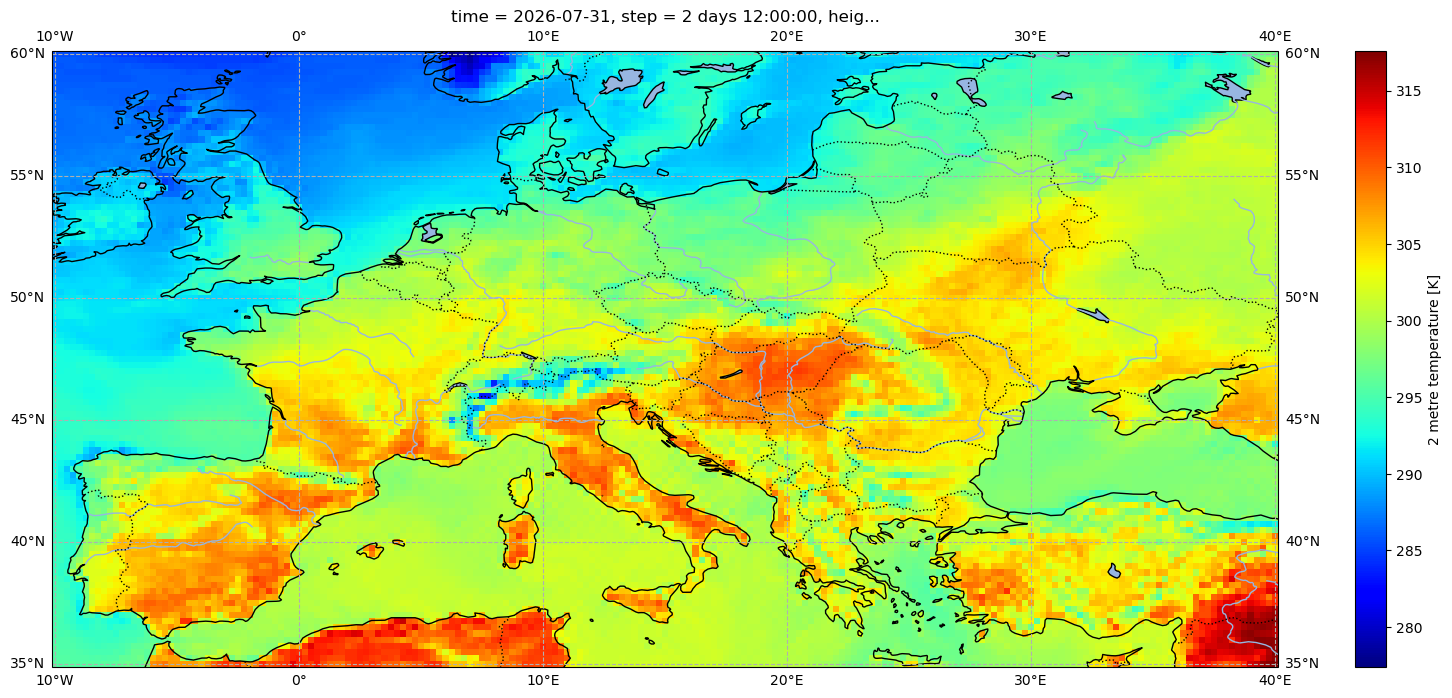

In [26]:
plot_t2m_forecast(temperature2m_3)

## Is the temperature going to increase or decrease ?
We can translate the forecast maps into natural language to help the users of our forecast application to understand what will be the temperature in the next couple of days. We can also calculate the difference between tomorrow and today and then between tomorrow and 2 days from now to have a better picture of the temperature dynamic.

In [24]:
t2m_1_2_diff =  temperature2m_2 - temperature2m_1

The blue areas is where the temperature will decrease tomorrow. Orange and yellow is where it will increase and green is where there will be no noticeable change

In [25]:
print('Mean 2m temperature difference: {:.2f} °C'.format(t2m_1_2_diff.mean().values))

Mean 2m temperature difference: -0.04 °C


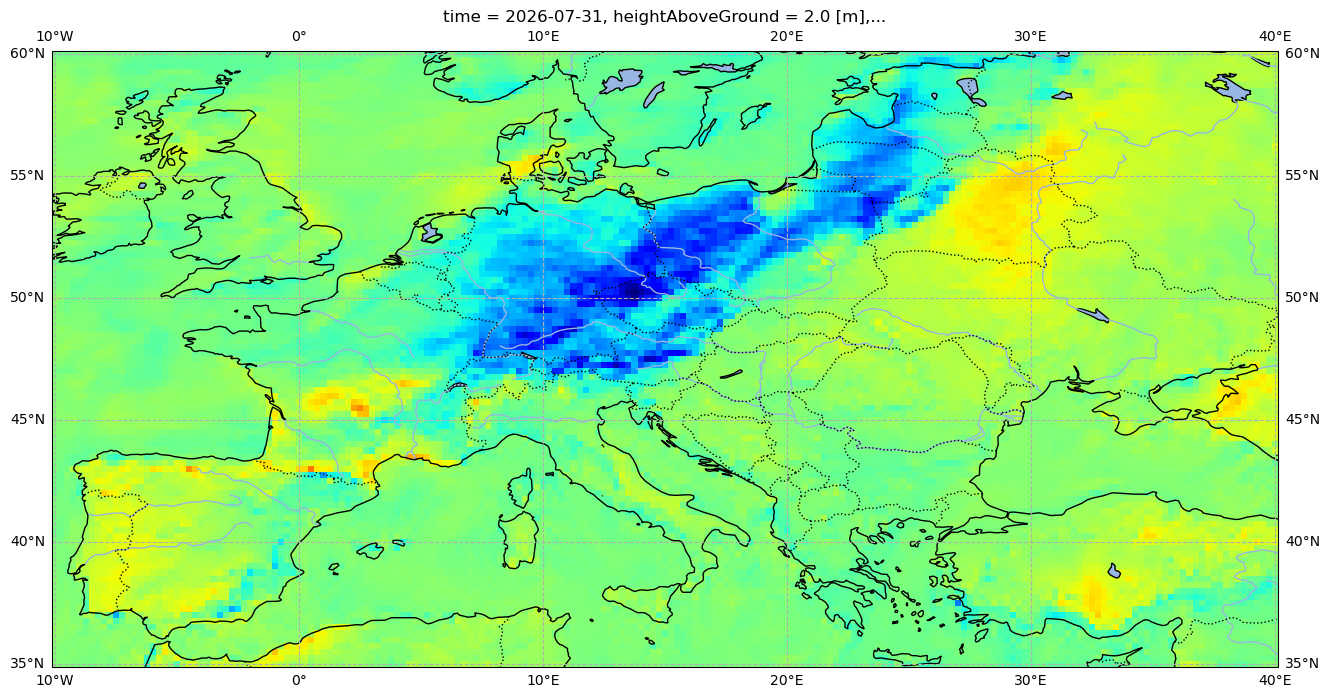

In [26]:
plot_t2m_forecast(t2m_1_2_diff, colorbar=False)

We can calculate the change from today to the next couple of days as well

In [27]:
t2m_2_3_diff =  temperature2m_3 - temperature2m_2

In [28]:
print('Mean 2m temperature difference: {:.2f} °C'.format(t2m_2_3_diff.mean().values))

Mean 2m temperature difference: 0.24 °C


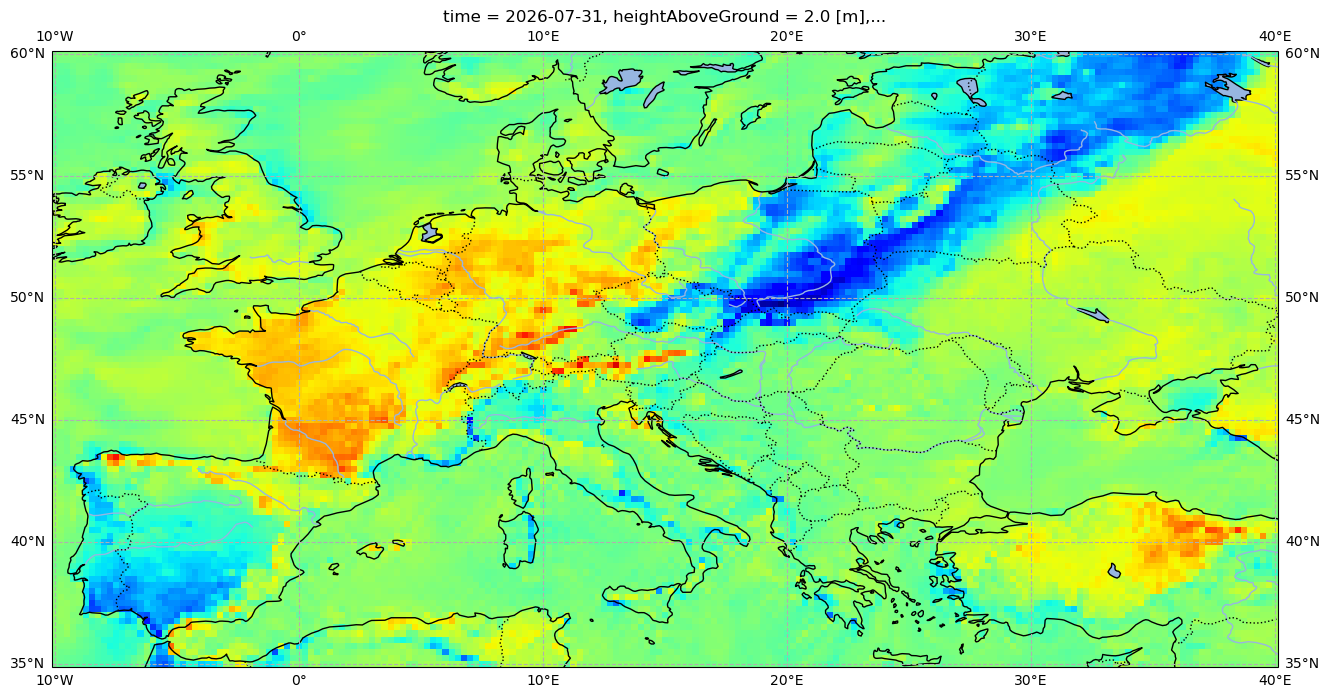

In [29]:
plot_t2m_forecast(t2m_2_3_diff, colorbar=False);

## Mean sea level pressure
Many other variables are available from the ECMWF Open Data service, one of these is the mean sea level pressure (msl). We will not go into the details but it would be interesting to plot the difference of the msl for the same days to see what the relation between the 2m surface temperature and the pressure at the ground level is. We define another function to draw the contour plot of the pressure field.

In [27]:
mean_sl_pressure_1 = ds1['msl'].sel(latitude = slice(bb_north, bb_south),
                                 longitude = slice(bb_west, bb_east))

In [28]:
def plot_msl(xr_dataset):
    plt.figure(figsize=(20,10))
    ax = plt.axes(projection=ccrs.PlateCarree())
    ax.gridlines(draw_labels=True, linestyle='--')
    ax.add_feature(cartopy.feature.OCEAN)
    ax.add_feature(cartopy.feature.LAND, edgecolor='black')
    ax.add_feature(cartopy.feature.LAKES, edgecolor='black')
    ax.add_feature(cartopy.feature.RIVERS)
    ax.add_feature(cfeature.BORDERS, linestyle=':')
    ax.coastlines()
    xr_dataset.plot.contour(ax=ax, add_colorbar=False, add_labels=True)

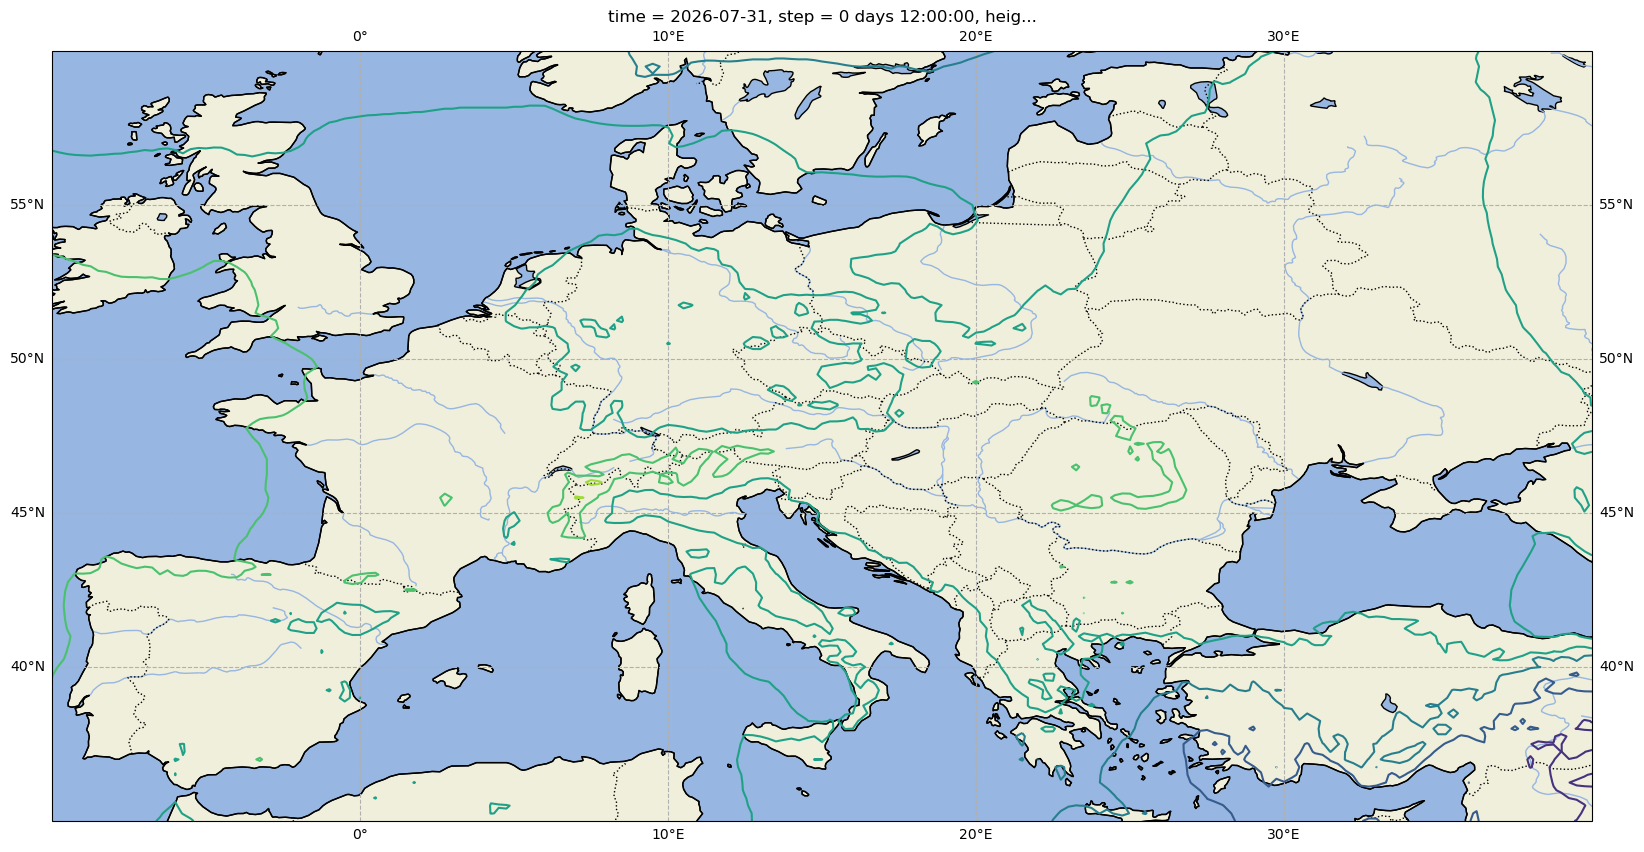

In [29]:
plot_msl(mean_sl_pressure_1);

## Conclusion
We have just scratched the surface of the ECMWF Open Data service. Many other weather variables can be downloaded and used to visualize the forecasts in a region of our interest or as a time series for the city where we live.

## References
* [ECMWF Open Data](https://www.ecmwf.int/en/forecasts/datasets/open-data)
* [ECMWF - Forecaster User Guide](https://confluence.ecmwf.int/spaces/FUG/pages/673550329/Section+1+Introduction)
* [ECMWF Codex](https://github.com/ecmwf/codex/tree/main), principles and guidelines for development of software and services at ECMWF

## Credit and license
The dataset used in this notebook is the “ECMWF IFS Forecast data, accessed from ECMWF’s MARS archive, © European Centre for Medium-Range Weather Forecasts (ECMWF), 2025. Licensed under CC-BY-4.0.”